In [1]:
!pip install gym gym_bandits

In [2]:
import gym

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
import gym_bandits

In [4]:
import numpy as np

In [5]:
import matplotlib.pyplot as plt

In [7]:
np.bool8 = np.bool_

Number of arms: 10

Epsilon-Greedy Results
-----------------------------
Q-values: [-0.63  0.    0.    0.    0.    0.    0.    0.    0.    0.  ]
Arm selection counts: [1 0 0 0 0 0 0 0 0 0]
Average reward: -0.6308950138710606

Epsilon-Greedy Results
-----------------------------
Q-values: [-0.63  0.    0.    0.    0.    0.   -0.07  0.    0.    0.  ]
Arm selection counts: [1 0 0 0 0 0 1 0 0 0]
Average reward: -0.34949953290016944

Epsilon-Greedy Results
-----------------------------
Q-values: [ 0.28  0.    0.    0.    0.    0.   -0.07  0.    0.    0.  ]
Arm selection counts: [2 0 0 0 0 0 1 0 0 0]
Average reward: 0.16169108825051826

Epsilon-Greedy Results
-----------------------------
Q-values: [ 0.18  0.    0.    0.    0.    0.   -0.07  0.    0.    0.  ]
Arm selection counts: [3 0 0 0 0 0 1 0 0 0]
Average reward: 0.11857411615903837

Epsilon-Greedy Results
-----------------------------
Q-values: [ 0.73  0.    0.    0.    0.    0.   -0.07  0.    0.    0.  ]
Arm selection counts: [4 0 0 0

/tmp/ipykernel_604/4129373172.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  q_values[action] += (reward - q_values[action]) / counts[action]


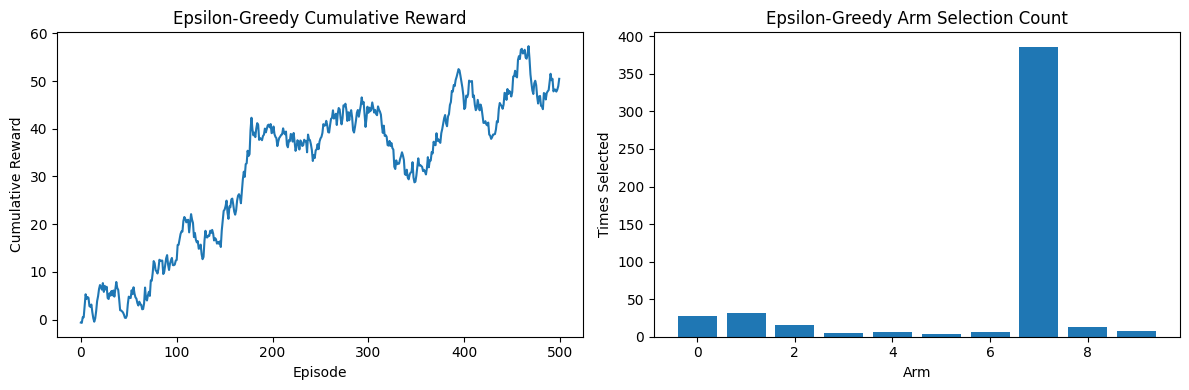


Softmax Results
-----------------------------
Q-values: [-2.51  0.04 -0.11 -0.03  0.09 -0.13 -0.13 -0.11 -2.65 -2.91]
Arm selection counts: [ 1 83 98 80 82 45 41 68  1  1]
Average reward: -0.05809224394455035


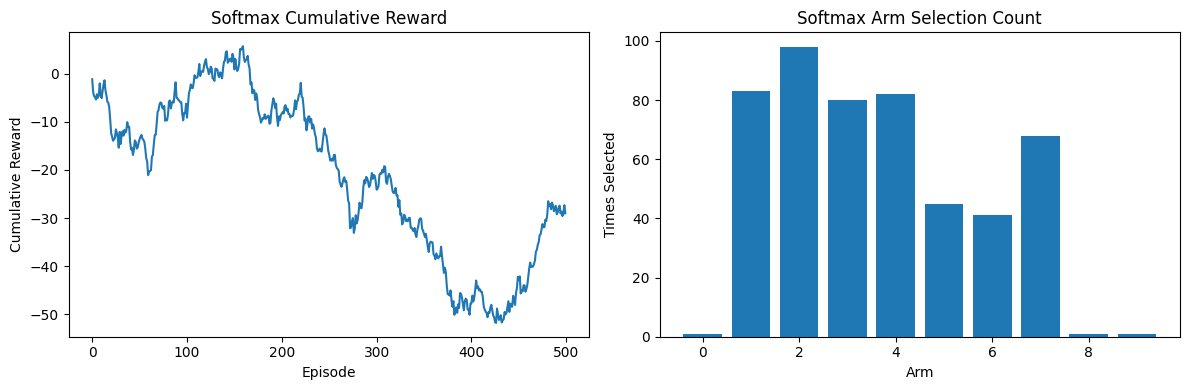

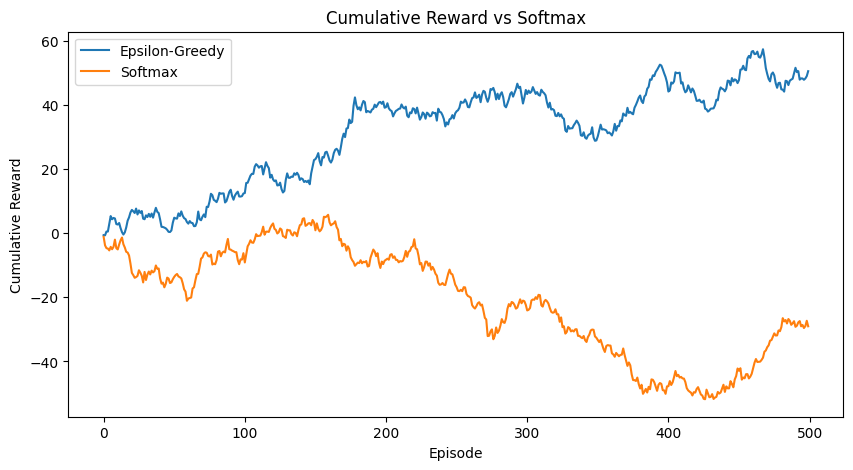

In [15]:
base_env = gym.make("MultiarmedBandits-v0")
env = base_env.unwrapped
n_arms = env.action_space.n
episodes = 500
print("Number of arms:", n_arms)
epsilon = 0.1
q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
rewards=[]
for episode in range(episodes):
  env.reset()

  if np.random.rand() < epsilon:
    action = env.action_space.sample()
  else:
    action = np.argmax(q_values)
  observation, reward, done, info = env.step(action)
  counts[action] += 1
  q_values[action] += (reward - q_values[action]) / counts[action]
  rewards.append(reward)
  print("\nEpsilon-Greedy Results")
  print("-----------------------------")
  print("Q-values:", np.round(q_values, 2))

  print("Arm selection counts:", counts.astype(int))
  print("Average reward:", np.mean(rewards))

plt.figure(figsize=(12, 4))


plt.subplot(1, 2, 1)


plt.plot(np.cumsum(rewards))


plt.title("Epsilon-Greedy Cumulative Reward")


plt.xlabel("Episode")


plt.ylabel("Cumulative Reward")


plt.subplot(1, 2, 2)


plt.bar(range(n_arms), counts)

plt.title("Epsilon-Greedy Arm Selection Count")


plt.xlabel("Arm")


plt.ylabel("Times Selected")


plt.tight_layout()


plt.show()

temperature = 0.5

q_values_softmax = np.zeros(n_arms)

counts_softmax = np.zeros(n_arms)

rewards_softmax = []


for episode in range(episodes):


    env.reset()


    probabilities = np.exp(q_values_softmax / temperature)


    probabilities = probabilities / np.sum(probabilities)


    action = np.random.choice(n_arms, p=probabilities)


    observation, reward, done, info = env.step(action)


    counts_softmax[action] += 1


    q_values_softmax[action] += (reward - q_values_softmax[action]) / counts_softmax[action]


    rewards_softmax.append(reward)

print("\nSoftmax Results")
print("-----------------------------")


print("Q-values:", np.round(q_values_softmax, 2))

print("Arm selection counts:", counts_softmax.astype(int))


print("Average reward:", np.mean(rewards_softmax))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(rewards_softmax))
plt.title("Softmax Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1, 2, 2)
plt.bar(range(n_arms), counts_softmax)
plt.title("Softmax Arm Selection Count")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(
    np.cumsum(rewards),
    label="Epsilon-Greedy"
)
plt.plot(
    np.cumsum(rewards_softmax),
    label="Softmax"
)
plt.title("Cumulative Reward vs Softmax")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.legend()
plt.show()
env.close()
